# GPT-2 from scratch: demo, tests, and experiments

This notebook demonstrates the whole project end to end, so it can be run without any local environment setup
(Colab, Kaggle, or locally). It will:

1. fetch the repository and install the (few) dependencies,
2. **run the unit tests**,
3. load the trained model and **show the tokenizer, tensor shapes, and next-token predictions**,
4. **generate stories** at different temperatures,
5. show the **training curves and experiment results**,
6. **visualise attention** (masked vs unmasked),
7. run a **small training job from scratch** (a few minutes) to show the training pipeline working.

No GPU is required. On Colab: *Runtime, Run all*. On Kaggle: import this notebook, turn Internet on, then *Run All*.

## 1. Setup

In [1]:
import os, sys

if not os.path.exists("src"):                     # not already inside the repository
    if os.path.exists("../src"):                  # running from the notebooks/ folder
        os.chdir("..")
    else:                                         # Colab / Kaggle: fetch the repository
        !git clone https://github.com/mesale/gpt2-from-scratch.git
        os.chdir("gpt2-from-scratch")
sys.path.insert(0, os.getcwd())
print("working directory:", os.getcwd())

Cloning into 'gpt2-from-scratch'...
remote: Enumerating objects: 211, done.
remote: Counting objects: 100% (211/211), done.
remote: Compressing objects: 100% (169/169), done.
remote: Total 211 (delta 77), reused 173 (delta 39), pack-reused 0 (from 0)
Receiving objects: 100% (211/211), 44.39 MiB | 27.85 MiB/s, done.
Resolving deltas: 100% (77/77), done.
working directory: /kaggle/working/gpt2-from-scratch


In [2]:
# PyTorch is preinstalled on Colab and Kaggle; install the rest (quietly)
!pip install -q tokenizers pyyaml pandas matplotlib pytest numpy

## 2. Run the unit tests
The suite checks the pieces of the architecture one by one: output shapes, **no leakage from future tokens**
(the causal mask), our attention against PyTorch's reference `scaled_dot_product_attention`, our LayerNorm against
`nn.LayerNorm`, initial loss close to ln(vocab), weight tying, overfitting a single batch, the LR schedule,
checkpoint resume, and generation.

In [3]:
!python -m pytest -q

.........................................                                [100%]
=============================== warnings summary ===============================
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
    prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))

../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
  /usr/local/l

## 3. Load the trained model and inspect it
The model is the 12.3M-parameter GPT trained on TinyStories (6 layers, 6 heads, width 384, context 256).

In [4]:
import torch
from src.checkpoint import load_model
from src.tokenizer import load_tokenizer, EOT

device = "cuda" if torch.cuda.is_available() else "cpu"
model = load_model("models/tinystories_main_best.pt", device)
tok = load_tokenizer("configs/tokenizer.json")
print(f"{sum(p.numel() for p in model.parameters()):,} parameters on {device}")
print(model.cfg)

12,318,720 parameters on cpu
GPTConfig(vocab_size=4096, block_size=256, n_layer=6, n_head=6, n_embd=384, dropout=0.0, bias=True, pre_ln=True, tie_weights=True)


In [5]:
# Tokenizer round trip, tensor shapes, and next-token prediction
text = "Once upon a time, there was a little girl named Lily."
enc = tok.encode(text)
print(len(enc.ids), "tokens:", enc.tokens)
assert tok.decode(enc.ids) == text                       # exact reconstruction

x = torch.tensor([[tok.token_to_id(EOT)] + enc.ids], device=device)   # start marker + text
logits, _ = model(x)
print("input ids", tuple(x.shape), "-> logits", tuple(logits.shape), "= (batch, tokens, vocabulary)")

probs = logits[0, -1].softmax(-1)                        # distribution over the NEXT token
top = probs.topk(5)
print("most likely next tokens:", [(tok.decode([i]), round(p, 3)) for p, i in zip(top.values.tolist(), top.indices.tolist())])

13 tokens: ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġthere', 'Ġwas', 'Ġa', 'Ġlittle', 'Ġgirl', 'Ġnamed', 'ĠLily', '.']
input ids (1, 14) -> logits (1, 14, 4096) = (batch, tokens, vocabulary)
most likely next tokens: [(' She', 0.745), (' Lily', 0.243), (' One', 0.009), (' Every', 0.0), (' Today', 0.0)]


## 4. Generate stories
`temperature=0` is greedy decoding; higher temperatures sample more diversely (and eventually less coherently).

In [6]:
from src.generate import sample_texts

prompt = "The little dog was sad because"
for temp in [0, 0.7, 1.0, 1.5]:
    print(f"\n=== temperature {temp} ===")
    for t in sample_texts(model, tok, prompt, n=1 if temp == 0 else 2, max_new_tokens=150,
                          temperature=temp, seed=0, device=device):
        print(t, "\n")


=== temperature 0 ===
The little dog was sad because he had no friends. He walked around the park, looking for someone to play with. He saw a big tree and thought, "Maybe I can find a friend there."
The little dog walked to the tree and saw a little girl. She was playing with a ball. The little dog walked up to her and said, "Hi, I am a dog. Do you want to play with me?" The little girl smiled and said, "Yes, I am Lily. I am a dog, but I have no friends."
The little dog was happy to have a new friend. They played together all day. The little dog was not sad anymore. He had a new friend, and they had lots of fun. 


=== temperature 0.7 ===
The little dog was sad because he was hungry. All the other dogs wanted food. The little dog looked around and saw a big bowl. The bowl was full of food, but the little dog was still hungry.
"Who takes my food?" the little dog asked. The big dog shook his head. "I am hungry," the little dog said. "I am hungry. I need a meal." The little dog was sad, 

In [7]:
# Try your own prompt
my_prompt = "One day, a girl named Mia found a magic key."
for t in sample_texts(model, tok, my_prompt, n=3, max_new_tokens=150, temperature=0.7, seed=1, device=device):
    print(t, "\n---\n")

One day, a girl named Mia found a magic key. This key could unlock a box with a key. Mia was very happy and wanted to find the key. She looked for the key every day.
One day, Mia saw a big, dangerous snake. She was scared, but she wanted to find the key. She asked her friend Tom, "Do you know where the key is?" Tom said, "I don't know, but let's look."
They looked and looked, but they could not find the key. Then, they saw a big, scary spider. The spider was not nice. It chased them and scared them. Mia and Tom tried to run away, but the spider caught them. The treasure was lost forever. 
---

One day, a girl named Mia found a magic key. The key could unlock a big box. Mia was very happy. She wanted to see what was inside the box. She looked around and saw a small door. Mia used the key to unlock the door.
Inside, Mia saw a small room with a big box. She opened the box and found a lot of toys. But, the toys were not in its place. The toys were for little kids. Mia was sad. She thought 

## 5. Training curves and experiment results
Read from the logs saved by each run in `results/`.

TinyStories main run: final val 1.3718, best val 1.3718
Tiny Shakespeare debug run (overfits): final val 3.6712, best val 3.6297


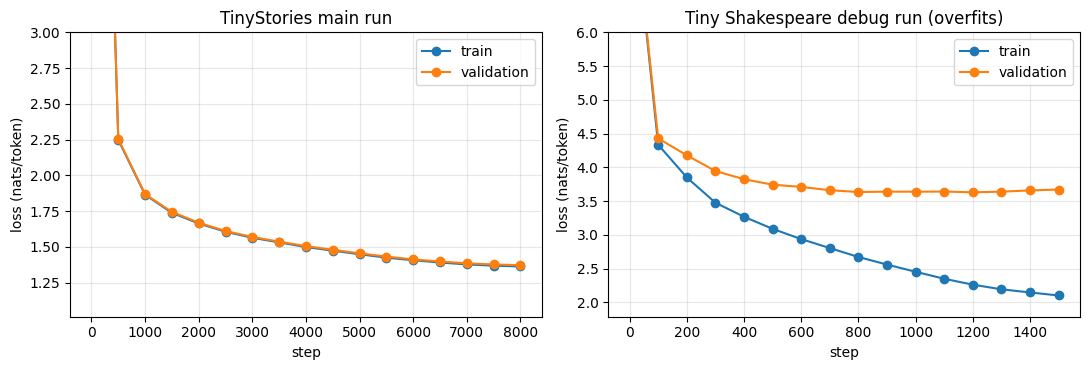

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, d, ymax) in zip(axes, [("TinyStories main run", "results/tinystories_main", 3.0),
                                      ("Tiny Shakespeare debug run (overfits)", "results/shakespeare_debug", 6.0)]):
    ev = pd.read_csv(f"{d}/eval_log.csv")
    ax.plot(ev.step, ev.train_loss, "o-", label="train")
    ax.plot(ev.step, ev.val_loss, "o-", label="validation")
    ax.set_title(name); ax.set_xlabel("step"); ax.set_ylabel("loss (nats/token)")
    ax.set_ylim(top=ymax); ax.legend(); ax.grid(alpha=0.3)
    print(f"{name}: final val {ev.val_loss.iloc[-1]:.4f}, best val {ev.val_loss.min():.4f}")
plt.tight_layout(); plt.show()

In [9]:
import pandas as pd

# Number of attention heads (same parameter count, 1,500 steps each)
print(pd.read_csv("results/ablation_heads/summary.csv").to_string(index=False))
print()
# Pre-LN vs post-LN
print(pd.read_csv("results/ablation_ln/summary.csv").to_string(index=False))

          run  heads  head_dim  final_val  best_val    tok_per_s
      heads_1      1       384   1.719831  1.719831 89596.380935
      heads_2      2       192   1.711889  1.711889 81853.160046
      heads_6      6        64   1.702770  1.702770 59406.347306
     heads_12     12        32   1.704621  1.704621 59004.390643
heads_6_seed2      6        64   1.698366  1.698366 71211.056969

                      run  final_val  best_val
pre-LN lr1e-3 (seed 1337)   1.702770  1.702770
pre-LN lr1e-3 (seed 1338)   1.698366  1.698366
            postln_lr1e-3   5.888070  5.887936
            postln_lr3e-4   2.458308  2.458308
             preln_lr3e-4   1.973289  1.973289


In [10]:
import pandas as pd

# Context length: loss on fixed target tokens when the model sees only the previous k tokens
print(pd.read_csv("results/analysis/loss_vs_context.csv").to_string(index=False))
print()
print(pd.read_csv("results/analysis/temperature_metrics.csv").round(3).to_string(index=False))

context     loss
      1 3.949665
      2 3.305691
      4 2.795922
      8 2.363938
     16 2.027053
     32 1.741590
     64 1.535513
    127 1.428546
   full 1.410583

 temperature  rep3  mean_words  pct_ended  distinct2
         0.0 0.074     133.740      0.660        NaN
         0.3 0.070     135.615      0.635      0.674
         0.7 0.039     136.725      0.600      0.777
         1.0 0.018     134.390      0.590      0.861
         1.5 0.001     123.330      0.405      0.986


## 5b. Why divide by sqrt(d_k)? (scaled dot-product attention in numbers)
For random queries and keys with unit-variance entries, the dot product has variance d_k, so scores grow with the head
size and softmax saturates (almost one-hot), which starves the gradients. Dividing by sqrt(d_k) restores variance 1.

In [11]:
import torch
torch.manual_seed(0)
d_k = 64
q, k = torch.randn(10000, d_k), torch.randn(10000, d_k)
dots = (q * k).sum(-1)
print(f"variance of q.k  without scaling: {dots.var().item():.1f}   with 1/sqrt(d_k): {(dots / d_k ** 0.5).var().item():.2f}")

scores = torch.tensor([2.0, 1.0, 0.1])
print("softmax of typical scores         :", scores.softmax(-1).numpy().round(3))
print("softmax if scores were 8x larger  :", (scores * 8).softmax(-1).numpy().round(3), " <- saturated")

variance of q.k  without scaling: 64.0   with 1/sqrt(d_k): 1.00
softmax of typical scores         : [0.659 0.242 0.099]
softmax if scores were 8x larger  : [1. 0. 0.]  <- saturated


## 6. Visualise attention: masked vs unmasked
Left: the real **causal** attention (a token can only look at itself and earlier tokens, so the upper triangle is exactly 0).
Right: the same trained weights with the mask removed, which shows what the mask forbids. (The model was never trained
this way, so the right-hand patterns are an intervention, not a different model.)

layer 0: without the mask, an average of 46.1% of attention would go to FUTURE tokens (causal: 0%)


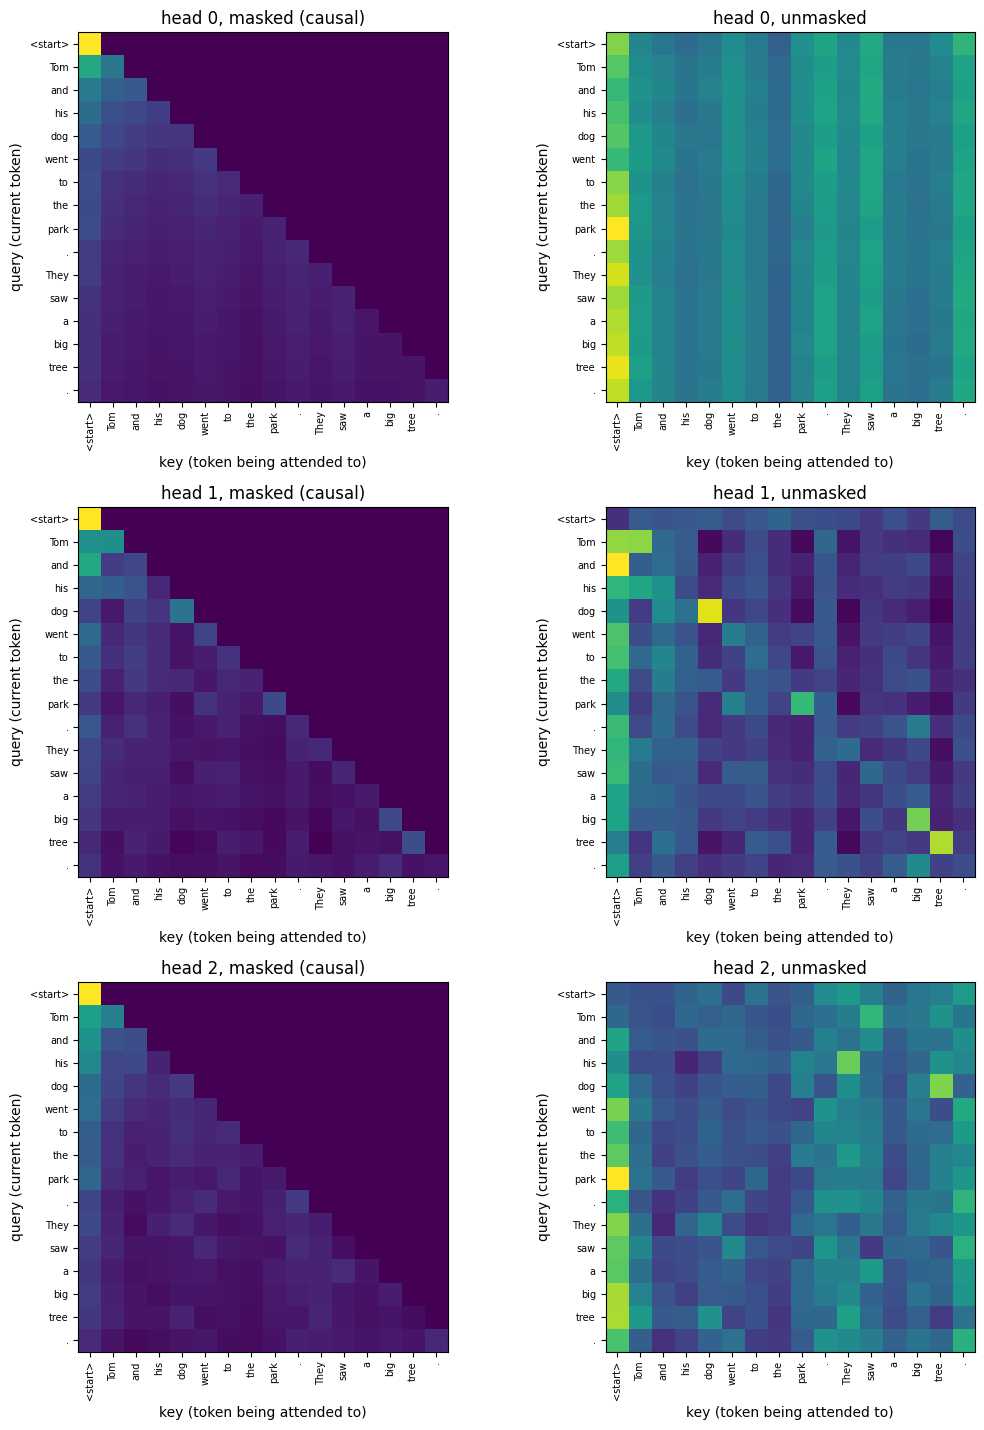

layer 5: without the mask, an average of 43.7% of attention would go to FUTURE tokens (causal: 0%)


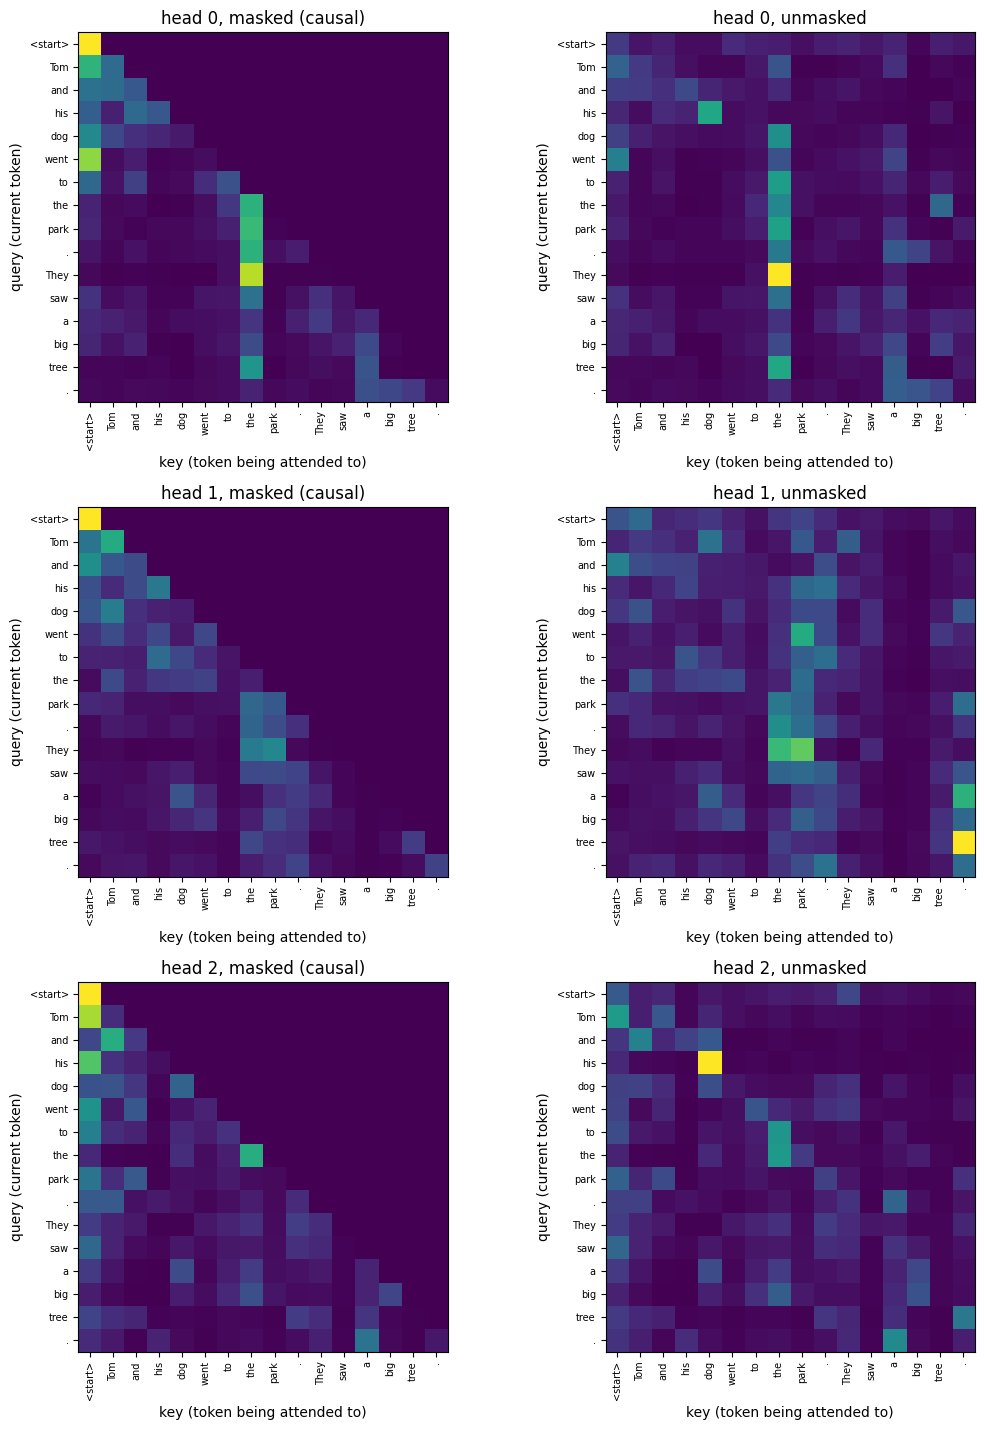

In [12]:
import os
import matplotlib.pyplot as plt
from src.viz import attention_maps, plot_attention

story = "Tom and his dog went to the park. They saw a big tree."
ids = [tok.token_to_id(EOT)] + tok.encode(story).ids
idx = torch.tensor([ids], device=device)
labels = [tok.decode([i]).strip() or "_" for i in ids]
labels[0] = "<start>"

os.makedirs("results/figures", exist_ok=True)
for layer in (0, model.cfg.n_layer - 1):
    masked = attention_maps(model, idx, layer, causal=True)
    full = attention_maps(model, idx, layer, causal=False)
    future = full.triu(1).sum(-1).mean().item()
    print(f"layer {layer}: without the mask, an average of {future:.1%} of attention would go to FUTURE tokens (causal: 0%)")
    plot_attention(labels, masked, full, heads=(0, 1, 2), save_path=f"results/figures/attention_layer{layer}.png")
    plt.show()

## 7. Train a small model from scratch (a few minutes)
This runs the real training pipeline (`python -m src.train`: AdamW, warmup + cosine schedule, gradient clipping,
evaluation, checkpointing) on Tiny Shakespeare with a deliberately small model so it finishes quickly, even on CPU.

In [13]:
import os, urllib.request
import torch
from src.data import encode_file
from src.tokenizer import load_tokenizer

tok = load_tokenizer("configs/tokenizer.json")
device = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs("demo_data", exist_ok=True)
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = urllib.request.urlopen(url).read().decode("utf-8")
cut = int(0.9 * len(text))
for name, chunk in [("shk_train", text[:cut]), ("shk_val", text[cut:])]:
    with open(f"demo_data/{name}.txt", "w", encoding="utf-8") as f:
        f.write(chunk)
    print(name, f"{encode_file(f'demo_data/{name}.txt', f'demo_data/{name}.bin', tok):,} tokens")

shk_train 404,778 tokens
shk_val 46,915 tokens


In [14]:
!python -m src.train --config configs/shakespeare.yaml --set train.data_dir=demo_data train.out_dir=demo_runs train.run_name=tiny_demo train.max_steps=300 train.eval_interval=100 train.eval_iters=10 train.log_interval=25 train.batch_size=16 train.warmup_steps=20 train.resume=false model.n_layer=2 model.n_head=2 model.n_embd=128 model.block_size=128 model.dropout=0.1

937,472 params | 2,048 tokens/step | device=cpu amp=False
[eval] step 0: train 8.3216 | val 8.3138
step     25 | loss 7.5242 | lr 1.00e-03 | gnorm 1.15 | 10,252 tok/s
step     50 | loss 5.9330 | lr 9.76e-04 | gnorm 0.90 | 10,730 tok/s
step     75 | loss 5.4872 | lr 9.20e-04 | gnorm 0.49 | 10,617 tok/s
step    100 | loss 5.2627 | lr 8.35e-04 | gnorm 0.61 | 10,755 tok/s
[eval] step 100: train 5.1031 | val 4.9289
step    125 | loss 5.0197 | lr 7.27e-04 | gnorm 0.67 | 10,541 tok/s
step    150 | loss 4.8682 | lr 6.05e-04 | gnorm 0.72 | 10,721 tok/s
step    175 | loss 4.7692 | lr 4.80e-04 | gnorm 0.70 | 10,565 tok/s
step    200 | loss 4.6916 | lr 3.59e-04 | gnorm 0.70 | 10,580 tok/s
[eval] step 200: train 4.6160 | val 4.5659
step    225 | loss 4.6384 | lr 2.54e-04 | gnorm 0.82 | 10,546 tok/s
step    250 | loss 4.5805 | lr 1.72e-04 | gnorm 0.65 | 10,441 tok/s
step    275 | loss 4.5724 | lr 1.19e-04 | gnorm 0.74 | 10,648 tok/s
step    300 | loss 4.5420 | lr 1.00e-04 | gnorm 0.73 | 10,675 tok/s

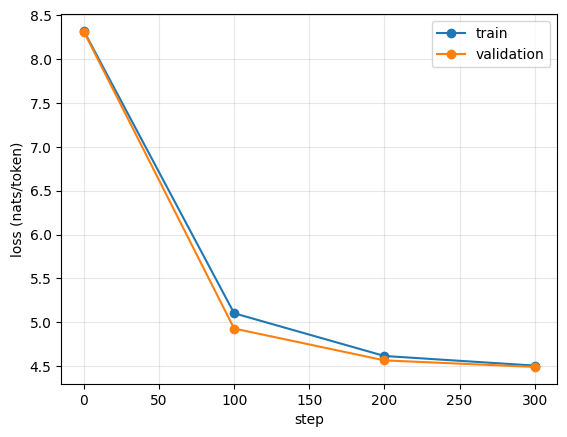

loss fell from 8.31 (about ln 4096 = 8.32) to 4.49
ROMEO:
Are you are you:
CEST:

That prrisapt.
That I bequion and that now shall not a prilue,

INUSuffs, yet canken; that thee, yet, for the bed


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from src.checkpoint import load_model
from src.generate import sample_texts

ev = pd.read_csv("demo_runs/tiny_demo/eval_log.csv")
plt.plot(ev.step, ev.train_loss, "o-", label="train"); plt.plot(ev.step, ev.val_loss, "o-", label="validation")
plt.xlabel("step"); plt.ylabel("loss (nats/token)"); plt.legend(); plt.grid(alpha=0.3); plt.show()
print("loss fell from", round(ev.val_loss.iloc[0], 2), "(about ln 4096 = 8.32) to", round(ev.val_loss.iloc[-1], 2))

small = load_model("demo_runs/tiny_demo/best.pt", device)
print(sample_texts(small, tok, "ROMEO:", n=1, max_new_tokens=60, temperature=0.8, seed=0, device=device, use_bos=False)[0])

## Summary
* The unit tests passed, including causality (no information flows from future tokens) and agreement with PyTorch's reference attention.
* The trained model writes coherent short stories; temperature trades diversity against coherence.
* The training pipeline runs end to end from raw text to a generating model.

Everything else (full report, all experiment logs and figures) is in `report/` and `results/`.